# Classificação e análise de sentimento com Large Language Models

- **Repositório:** `nlp-llms-portfolio`  
- **Tecnologias:** Transformers, PyTorch  
- **Arquivo Original:** `Sentiment_Analysis_using_LLM_share.ipynb`  

---


Renan Antonio Hammerschmidt Krefta

Victor Silva Camargo

Vinícius Silva Camargo

In [1]:
import locale
def getpreferredencoding(do_setlocale = True):
    return "UTF-8"
locale.getpreferredencoding = getpreferredencoding
!nvidia-smi

Fri Nov  7 20:50:50 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 550.54.15              Driver Version: 550.54.15      CUDA Version: 12.4     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   57C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
!pip install -q transformers peft datasets accelerate bitsandbytes torch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.4/59.4 MB 17.2 MB/s eta 0:00:00


In [3]:
from transformers import AutoModelForCausalLM, AutoTokenizer
import torch
from datasets import load_dataset
from tqdm.autonotebook import tqdm
from sklearn.metrics import classification_report
from sklearn import metrics
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
dataset = load_dataset("sst2")["validation"].to_pandas().drop("idx",axis=1).sample(n=25, random_state=1)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/3.11M [00:00<?, ?B/s]

data/validation-00000-of-00001.parquet:   0%|          | 0.00/72.8k [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/148k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/67349 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/872 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1821 [00:00<?, ? examples/s]

In [5]:
BASE_MODEL = "mistralai/Mistral-7B-v0.1"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL)
tokenizer.pad_token = tokenizer.eos_token

base_model = AutoModelForCausalLM.from_pretrained(
    BASE_MODEL,
    dtype=torch.bfloat16 if DEVICE == "cuda" else torch.float32,
    device_map="auto",
    load_in_4bit=True,
)

tokenizer_config.json:   0%|          | 0.00/996 [00:00<?, ?B/s]

tokenizer.model:   0%|          | 0.00/493k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/414 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

...

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

model-00001-of-00002.safetensors:   0%|          | 0.00/9.94G [00:00<?, ?B/s]

model-00002-of-00002.safetensors:   0%|          | 0.00/4.54G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

In [6]:
dataset

,sentence,label
523,a romantic comedy enriched by a sharp eye for ...,1
731,but what are adults doing in the theater at al...,0
180,"unfortunately , it 's not silly fun unless you...",0
185,a must-see for the david mamet enthusiast and ...,1
435,a marvel like none you 've seen .,1
34,"it does n't believe in itself , it has no sens...",0
73,"one of creepiest , scariest movies to come alo...",1
59,it 's just disappointingly superficial -- a mo...,0
725,( grant 's ) bumbling magic takes over the fil...,1
2,allows us to hope that nolan is poised to emba...,1


In [7]:
import re # Adicione esta importação no topo da sua célula de imports

# Voce pode alterar esta função como achar melhor, esta é somente uma base inicial.
def sentiment_analysis(sentence):

  prompt = sentence
  prompt_template=f'''[INST] using only 0 or 1. 0 for negative and 1 for positive. Write the sentiment of the following sentence: "{prompt}". Sentiment: [/INST]
  ''' # TASK 1 - Pense que o que for colocar neste texto será o input puro do LLM, se atente para como o modelo foi treinado -> https://huggingface.co/mistralai/Mistral-7B-Instruct-v0.1

  input_ids = tokenizer(prompt_template, return_tensors='pt')
  output = base_model.generate(
      inputs=input_ids.input_ids.cuda(),
      attention_mask=input_ids.attention_mask.cuda(),
      pad_token_id=tokenizer.eos_token_id,
      max_new_tokens=10
)

  res = tokenizer.decode(output[0])

  # --- INÍCIO DA CORREÇÃO (TASK 2) ---
  # Aqui usamos Regex (re) para encontrar o primeiro dígito (0 ou 1)
  # que aparece logo após o marcador [/INST].
  match = re.search(r'\[/INST\]\s*(\d)', res)

  if match:
      # Se encontrou (ex: "...[/INST] 1"), retorna o dígito como um inteiro
      return int(match.group(1))
  else:
      # Se o modelo não respondeu como esperado, retorna None
      # A próxima célula já tem um .dropna() que vai limpar isso.
      return None
  # --- FIM DA CORREÇÃO ---

In [8]:
save_sentiment_compute = {}
for i,v in tqdm(dataset.iterrows()):

  print(v["sentence"])
  res = sentiment_analysis(v["sentence"])
  print(res)

  try:
    save_sentiment_compute[i] = res # TASK 2 - Aqui voce pode salvar "res" diretamente na varável "save_sentiment_compute" ou trata-la antes.
  except:
    save_sentiment_compute[i] = None

  print("-"*100)

0it [00:00, ?it/s]

a romantic comedy enriched by a sharp eye for manners and mores . 
1
----------------------------------------------------------------------------------------------------
but what are adults doing in the theater at all ? 
1
----------------------------------------------------------------------------------------------------
unfortunately , it 's not silly fun unless you enjoy really bad movies . 
1
----------------------------------------------------------------------------------------------------
a must-see for the david mamet enthusiast and for anyone who appreciates intelligent , stylish moviemaking . 
1
----------------------------------------------------------------------------------------------------
a marvel like none you 've seen . 
1
----------------------------------------------------------------------------------------------------
it does n't believe in itself , it has no sense of humor ... it 's just plain bored . 
1
-----------------------------------------------------------

# Standart prompting

count    24.0
mean      1.0
std       0.0
min       1.0
25%       1.0
50%       1.0
75%       1.0
max       1.0
Name: prediction, dtype: float64
count    25.000000
mean      0.480000
std       0.509902
min       0.000000
25%       0.000000
50%       0.000000
75%       1.000000
max       1.000000
Name: label, dtype: float64


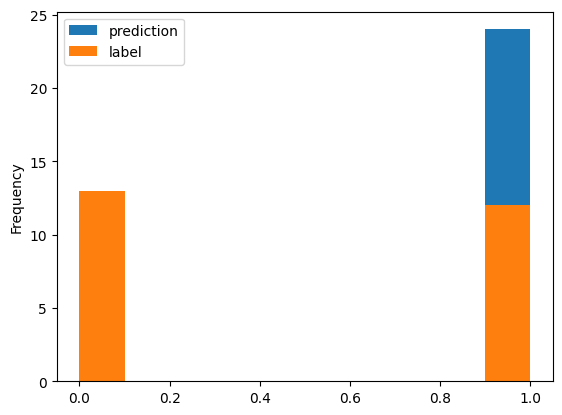

prediction_binary_0_5
               precision    recall  f1-score   support

           0       0.00      0.00      0.00        13
           1       0.46      1.00      0.63        11

    accuracy                           0.46        24
   macro avg       0.23      0.50      0.31        24
weighted avg       0.21      0.46      0.29        24



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [9]:
combine = pd.concat([
    dataset,
    pd.Series(save_sentiment_compute,name="prediction")
],axis=1)

print(combine["prediction"].describe())
print(combine["label"].describe())

# Até aqui é esperado que a variável combine seja um dataframe com 3 colunas (sentence, label e prediction)
# Para determinarmos se seu metodo funcionou, testaremos a coluna label com a coluna prediction.
# Como trata-se de de um problema de classificação, seu coluna prediction neste momento dever ser um INT (0 ou 1).

combine[["prediction","label"]].plot(kind="hist",bins=10)
plt.show()

# TASK 3 - A função sentiment_analysis agora retorna um número ou None.
# A linha abaixo (dropna) cuida dos 'None', então nenhuma manipulação extra é necessária.

# Drop rows where prediction is None
combine.dropna(subset=["prediction"], inplace=True)

print("prediction_binary_0_5\n",classification_report(combine["label"],combine["prediction"]))